In [1]:
import numpy as np
print(np.__version__)
print(np.__file__)

2.5.1
C:\Users\hp\.conda\envs\notebook-env\Lib\site-packages\numpy\__init__.py


In [1]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import tensorflow 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Conv2D,MaxPooling2D,Flatten,InputLayer
from tensorflow.keras.datasets import mnist

In [4]:
(train_images,train_labels),(test_images,test_labels)=mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [5]:
train_images.shape

(60000, 28, 28)

In [6]:
test_images.shape

(10000, 28, 28)

In [7]:
test_images.shape

(10000, 28, 28)

In [8]:
print('minimum pixel:',train_images.min())
print('maximum pixel:',train_images.max())

minimum pixel: 0
maximum pixel: 255


In [9]:
train_images,test_images=train_images/255.0,test_images/255.0

In [10]:
print('minimum pixel value:',train_images.min())
print('maximum pixel value:',train_images.max())

minimum pixel value: 0.0
maximum pixel value: 1.0


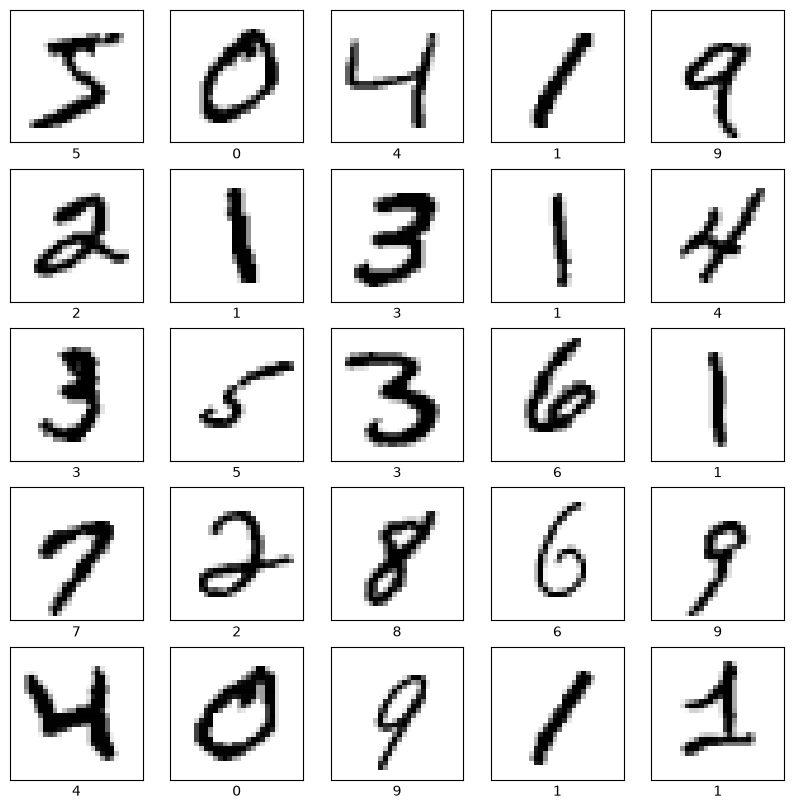

In [11]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i],cmap=plt.cm.binary)
    plt.xlabel(train_labels[i])
plt.show()

In [12]:
model=Sequential()
model.add(InputLayer(input_shape=(28,28,1)))
model.add(Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)))
model.add(MaxPooling2D(2,2))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Flatten())
model.add(Dense(64,activation='relu'))
model.add(Dense(10,activation='softmax'))
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

C:\Users\hp\.conda\envs\notebook-env\Lib\site-packages\keras\src\layers\core\input_layer.py:29: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
C:\Users\hp\.conda\envs\notebook-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,554 (236.54 KB)

 Trainable params: 60,554 (236.54 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.fit(train_images,train_labels,epochs=2,validation_data=(test_images,test_labels))

Epoch 1/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 52s 27ms/step - accuracy: 0.9336 - loss: 0.2151 - val_accuracy: 0.9710 - val_loss: 0.0944
Epoch 2/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 50s 27ms/step - accuracy: 0.9763 - loss: 0.0752 - val_accuracy: 0.9782 - val_loss: 0.0808


In [15]:
predicted=model.predict(test_images)

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step


In [16]:
predicted.shape

(10000, 10)

In [17]:
pred=np.argmax(predicted,axis=1)

In [18]:
pred.shape

(10000,)

In [19]:
loss,accuracy=model.evaluate(test_images,test_labels)

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9782 - loss: 0.0808


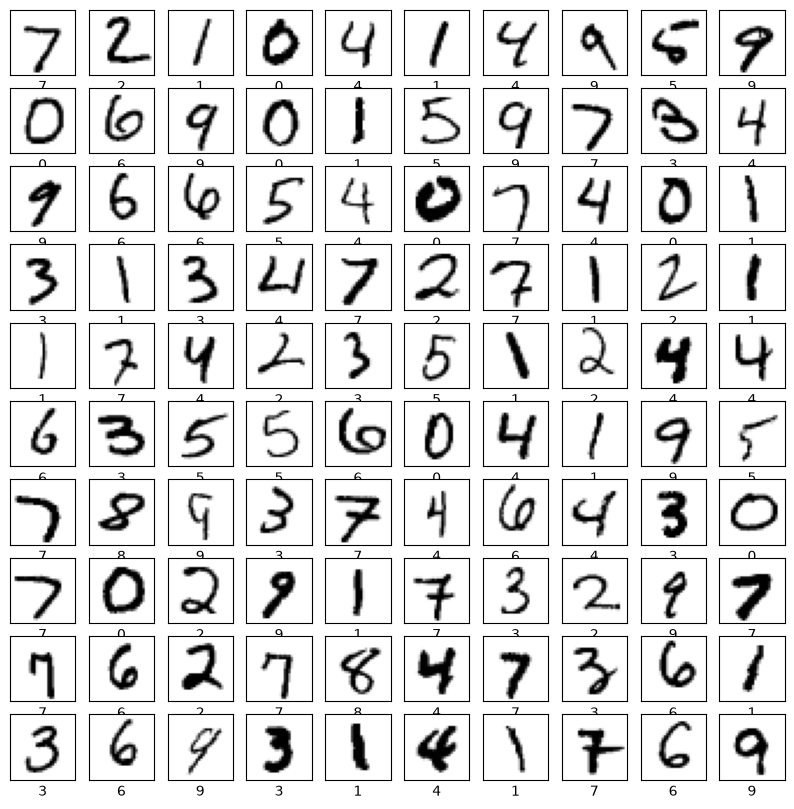

In [20]:
plt.figure(figsize=(10,10))
for i in range(100):
    plt.subplot(10,10,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i],cmap=plt.cm.binary)
    plt.xlabel(pred[i])
plt.show()

In [21]:
cm=confusion_matrix(test_labels,pred)
cm

array([[ 967,    1,    2,    1,    2,    1,    1,    5,    0,    0],
       [   0, 1127,    2,    3,    0,    0,    0,    3,    0,    0],
       [   1,    0, 1011,    2,    2,    0,    1,   15,    0,    0],
       [   0,    0,    0, 1006,    0,    1,    0,    3,    0,    0],
       [   1,    0,    1,    0,  975,    0,    1,    0,    0,    4],
       [   3,    0,    1,   16,    1,  868,    1,    1,    0,    1],
       [   8,    5,    1,    0,   13,    6,  923,    0,    1,    1],
       [   0,    1,   12,    8,    1,    0,    0, 1004,    1,    1],
       [   3,    1,    7,   12,    8,    6,    1,    4,  921,   11],
       [   4,    0,    0,    3,    9,    5,    0,    7,    1,  980]])

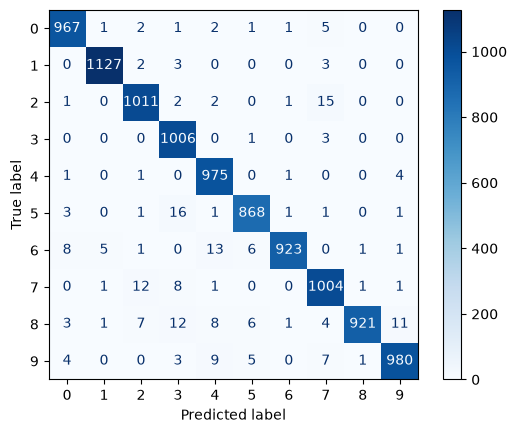

In [22]:
disp=ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')

In [23]:
total = cm.sum()

correct = np.trace(cm)

incorrect = total - correct

print("Total:", total)
print("Correct:", correct)
print("Incorrect:", incorrect)

Total: 10000
Correct: 9782
Incorrect: 218


In [24]:
import numpy as np

incorrect_indices = np.where(test_labels != pred)[0]

print("Number of incorrect images:", len(incorrect_indices))

Number of incorrect images: 218


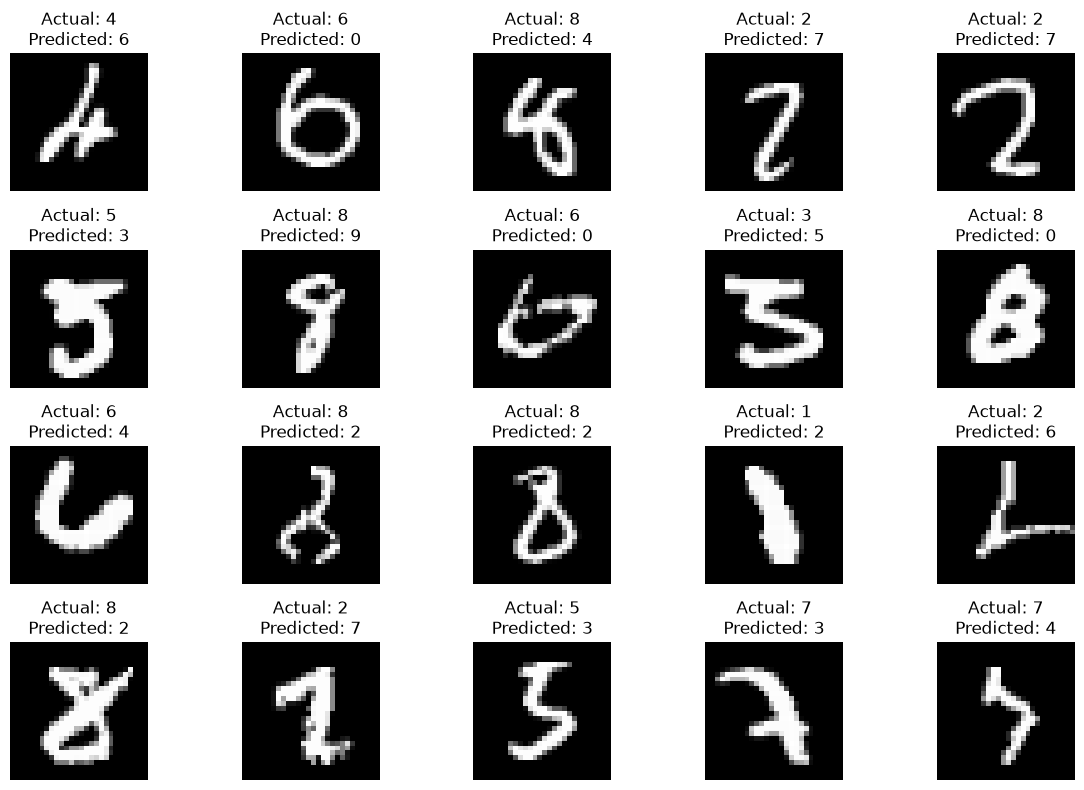

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i, index in enumerate(incorrect_indices[:20]):
    plt.subplot(4, 5, i + 1)
    
    plt.imshow(test_images[index].reshape(28, 28), cmap='gray')
    
    plt.title(f"Actual: {test_labels[index]}\nPredicted: {pred[index]}")
    plt.axis('off')

plt.tight_layout()
plt.show()